# Part 1 · Data understanding & validation

**Project:** Where do purchases get stuck? — P2P bottleneck analysis on SAP data
**Dataset:** BPI Challenge 2019 — purchase-to-pay event log of a multinational coatings & paints company (SAP), [DOI 10.4121/uuid:d06aff4b-79f0-45e6-8ec8-e19730c248f1](https://doi.org/10.4121/uuid:d06aff4b-79f0-45e6-8ec8-e19730c248f1), CC BY 4.0.

**Goal of this notebook:** load the event log, check its size and quality, and define the analysis scope before any process discovery.
In a Celonis project this corresponds to *loading and validating the data model*.

| Notebook | Question |
|---|---|
| **01 · Data understanding** | What is in the log, and is it reliable? |
| 02 · Process discovery | What does the real process look like? |
| 03 · Bottleneck & rework | Where is time lost? |
| 04 · Business impact | How much does it cost (€)? |

## 0 · Load the event log

In [1]:
from pathlib import Path
import time
import pandas as pd

DATA = Path("data")
CACHE = DATA / "bpic2019.parquet"   # fast columnar copy of the raw XES

t0 = time.time()
if CACHE.exists():
    df = pd.read_parquet(CACHE)
else:
    import pm4py
    xes = next(DATA.glob("*.xes"))                      # raw log, ~730 MB, not versioned
    df = pm4py.read_xes(str(xes))
    df["time:timestamp"] = pd.to_datetime(df["time:timestamp"], utc=True).dt.tz_localize(None)
    for col in df.select_dtypes(include=["object", "string"]).columns:
        df[col] = df[col].astype("string")
    df.to_parquet(CACHE)

# XES standard names -> readable names
df = df.rename(columns={
    "case:concept:name": "case_id",          # purchase document + item (SAP EKKO/EKPO)
    "concept:name": "activity",
    "time:timestamp": "timestamp",
    "case:Item Category": "item_category",
    "org:resource": "resource",
})
print(f"Loaded {len(df):,} events x {df.shape[1]} columns in {time.time() - t0:.0f}s")
df[["case_id", "activity", "timestamp", "resource", "item_category"]].head()

Loaded 1,595,923 events x 21 columns in 0s


,case_id,activity,timestamp,resource,item_category
0,2000000000_00001,SRM: Created,2018-01-02 12:53:00,batch_00,"3-way match, invoice before GR"
1,2000000000_00001,SRM: Complete,2018-01-02 13:53:00,batch_00,"3-way match, invoice before GR"
2,2000000000_00001,SRM: Awaiting Approval,2018-01-02 13:53:00,batch_00,"3-way match, invoice before GR"
3,2000000000_00001,SRM: Document Completed,2018-01-02 13:53:00,batch_00,"3-way match, invoice before GR"
4,2000000000_00001,SRM: In Transfer to Execution Syst.,2018-01-02 13:53:00,batch_00,"3-way match, invoice before GR"


Each row is **one event** (one step of one purchase order item). Columns prefixed with `case:` are case-level attributes, repeated on every event of the case — the equivalent of joining the *activity table* and the *case table* of a Celonis data model.

## 1 · Log size

In [2]:
n_cases = df["case_id"].nunique()
n_events = len(df)
print(f"Cases (PO items): {n_cases:,}")
print(f"Events:           {n_events:,}")
print(f"Events per case:  {n_events / n_cases:.1f}")
print(f"Resources:        {df['resource'].nunique():,}")

Cases (PO items): 251,734
Events:           1,595,923
Events per case:  6.3
Resources:        628


## 2 · Activity overview
Frequency of each activity, measured both as **events** and as **% of cases** in which it occurs at least once.

In [3]:
activities = (
    df.groupby("activity")
      .agg(events=("activity", "size"), cases=("case_id", "nunique"))
      .sort_values("cases", ascending=False)
)
activities["% of cases"] = (100 * activities["cases"] / n_cases).round(1)
print(f"Distinct activities: {len(activities)}")
activities.head(20)

Distinct activities: 42


,events,cases,% of cases
activity,,,
Create Purchase Order Item,251734,251734,100.0
Record Goods Receipt,314097,234479,93.1
Record Invoice Receipt,228760,211379,84.0
Vendor creates invoice,219919,209946,83.4
Clear Invoice,194393,183677,73.0
Remove Payment Block,57136,55839,22.2
Create Purchase Requisition Item,46592,46592,18.5
Receive Order Confirmation,32065,32061,12.7
Change Quantity,21449,17590,7.0


## 3 · Time range & data quality
The log is expected to cover 2018 (plus early 2019). Events outside that window indicate recording errors.

In [4]:
years = df["timestamp"].dt.year
print("First event:", df["timestamp"].min())
print("Last event: ", df["timestamp"].max())
print()
print(years.value_counts().sort_index().rename("events").to_string())

outliers = df[(years < 2018) | (years > 2019)]
print(f"\nEvents outside 2018-2019: {len(outliers):,} "
      f"({100 * len(outliers) / n_events:.3f} %) in {outliers['case_id'].nunique():,} cases")

First event: 1948-01-26 22:59:00
Last event:  2020-04-09 21:59:00

timestamp
1948         10
1993          9
2001         22
2008         45
2015          3
2016          6
2017        223
2018    1550468
2019      45135
2020          2

Events outside 2018-2019: 320 (0.020 %) in 266 cases


## 4 · Item categories
The company uses four invoice-matching flows. The dominant one defines the scope of the analysis.

| Category | Meaning |
|---|---|
| 3-way match, invoice **before** GR | PO + goods receipt + invoice must match; the invoice may arrive first and is then **blocked for payment** until goods are received |
| 3-way match, invoice **after** GR | Same matching, but the invoice is only posted after the goods receipt |
| 2-way match | No goods receipt required (e.g. services): PO + invoice |
| Consignment | No invoice at PO level |

In [5]:
cat = df.drop_duplicates("case_id")["item_category"].value_counts()
pd.DataFrame({"cases": cat, "% of cases": (100 * cat / cat.sum()).round(1)})

,cases,% of cases
item_category,,
"3-way match, invoice before GR",221010,87.8
"3-way match, invoice after GR",15182,6.0
Consignment,14498,5.8
2-way match,1044,0.4


## 5 · Analysis scope
- **Item category:** *3-way match, invoice before GR* (dominant flow).
- **Time window:** cases that **start and end** between 1 Jan 2018 and 31 Jan 2019. Whole cases are dropped (not single events) to avoid truncated traces.

In [6]:
SCOPE = "3-way match, invoice before GR"
START, END = pd.Timestamp("2018-01-01"), pd.Timestamp("2019-02-01")

scope = df[df["item_category"] == SCOPE]
bounds = scope.groupby("case_id")["timestamp"].agg(["min", "max"])
valid = bounds[(bounds["min"] >= START) & (bounds["max"] < END)].index
scope = scope[scope["case_id"].isin(valid)].sort_values(["case_id", "timestamp"])

scope.to_parquet(DATA / "bpic2019_3way_before_gr.parquet")
n_scope = scope["case_id"].nunique()
print(f"Cases in scope:  {n_scope:,} ({100 * n_scope / n_cases:.1f} % of all cases)")
print(f"Events in scope: {len(scope):,}")

Cases in scope:  220,810 (87.7 % of all cases)
Events in scope: 1,233,410


## 6 · Activity frequency in scope
Activities split into the **standard flow** and **rework / exceptions** (steps that would not exist in an ideal process).

In [7]:
import duckdb
import matplotlib.pyplot as plt

# Same aggregation as section 2, written in SQL (DuckDB) as a cross-check
freq = duckdb.sql('''
    SELECT activity,
           COUNT(*)                                               AS events,
           COUNT(DISTINCT case_id)                                AS cases,
           ROUND(100.0 * COUNT(DISTINCT case_id)
                 / (SELECT COUNT(DISTINCT case_id) FROM scope), 1) AS pct_cases
    FROM scope
    GROUP BY activity
    ORDER BY cases DESC
    LIMIT 15
''').df()

REWORK = {"Remove Payment Block", "Change Quantity", "Change Price", "Delete Purchase Order Item",
          "Cancel Invoice Receipt", "Cancel Goods Receipt", "Change Approval for Purchase Order",
          "Change Delivery Indicator", "Vendor creates debit memo"}
freq["type"] = freq["activity"].map(lambda a: "Rework / exception" if a in REWORK else "Standard flow")
freq

,activity,events,cases,pct_cases,type
0,Create Purchase Order Item,220810,220810,100.0,Standard flow
1,Record Goods Receipt,222529,206276,93.4,Standard flow
2,Record Invoice Receipt,208891,199368,90.3,Standard flow
3,Vendor creates invoice,203152,198342,89.8,Standard flow
4,Clear Invoice,180156,173503,78.6,Standard flow
5,Remove Payment Block,54622,53590,24.3,Rework / exception
6,Create Purchase Requisition Item,42564,42564,19.3,Standard flow
7,Receive Order Confirmation,31266,31262,14.2,Standard flow
8,Change Quantity,19104,15586,7.1,Rework / exception
9,Change Price,11125,10066,4.6,Rework / exception


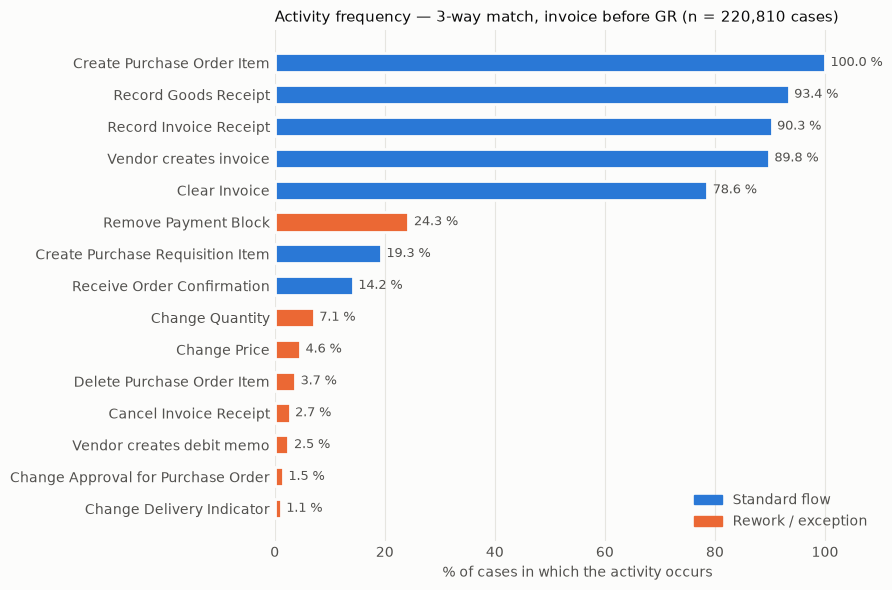

In [8]:
COLORS = {"Standard flow": "#2a78d6", "Rework / exception": "#eb6834"}
INK, MUTED, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"

plot = freq.iloc[::-1]   # largest on top
fig, ax = plt.subplots(figsize=(9, 6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
bars = ax.barh(plot["activity"], plot["pct_cases"], height=0.6,
               color=plot["type"].map(COLORS), edgecolor=SURFACE, linewidth=2)
for bar, v in zip(bars, plot["pct_cases"]):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2, f"{v:.1f} %",
            va="center", fontsize=9, color=MUTED)

ax.set_xlim(0, 110)
ax.set_xlabel("% of cases in which the activity occurs", color=MUTED)
ax.set_title("Activity frequency — 3-way match, invoice before GR (n = 220,810 cases)",
             loc="left", fontsize=11, color=INK)
ax.tick_params(colors=MUTED, length=0)
ax.grid(axis="x", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)
for s in ax.spines.values():
    s.set_visible(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS.values()]
ax.legend(handles, COLORS.keys(), loc="lower right", frameon=False, labelcolor=MUTED)
plt.tight_layout()

Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/01_activity_frequency.png", dpi=150, facecolor=SURFACE)
plt.show()

## Key findings
1. **Size.** The log contains **251,734 purchase order items** (cases) and **1.6 M events** (~6.3 events per case), handled by 628 resources, across **42 distinct activities**.
2. **Data quality is high but not perfect.** 99.98 % of events fall in 2018 – early 2019; **320 events (266 cases)** carry impossible dates (e.g. 1948, 2020) and are excluded.
3. **One flow dominates.** **87.8 %** of items follow *3-way match, invoice before GR*. The analysis focuses on this flow: **220,810 cases** after cleaning.
4. **The standard flow is clear:** *Create PO Item → Record Goods Receipt → Record Invoice Receipt → Clear Invoice*.
5. **Rework is significant.** In scope, **24.3 %** of cases need a *Remove Payment Block* (invoice received before the goods), **7.1 %** a *Change Quantity* and **4.6 %** a *Change Price*.

**Next step (Part 2):** discover the actual process map and variants, focusing on where payment blocks occur.